### **Universidad UTE**
#### _Algoritmo de regresión lineal_
#### Docente: Ing.Christian Rivadeneira Msc.
### Estudiante: Roberto Carlos Rocha Delgado
### Fecha: 30/10/2026

In [19]:
# Importacion de librerias
import pandas as pd
import matplotlib.pyplot as plt

In [20]:
data = pd.read_csv('Advertising.csv')
data.head(10)

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9
5,6,8.7,48.9,75.0,7.2
6,7,57.5,32.8,23.5,11.8
7,8,120.2,19.6,11.6,13.2
8,9,8.6,2.1,1.0,4.8
9,10,199.8,2.6,21.2,10.6


In [21]:
# Eliminamos del conjunto de datos la primer columna que contien
data = data.iloc[:, 1:]
data. head(5)

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [22]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [23]:
data.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [24]:
data.columns

Index(['TV', 'Radio', 'Newspaper', 'Sales'], dtype='str')

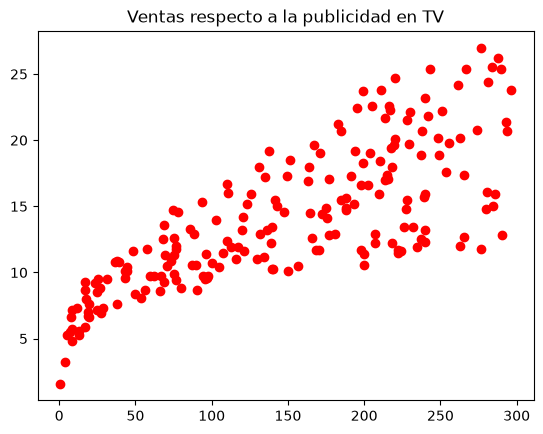

In [25]:
# Grafico
plt.plot(data['TV'], data['Sales'], 'ro')
plt.title('Ventas respecto a la publicidad en %s' % 'TV')
plt.show()

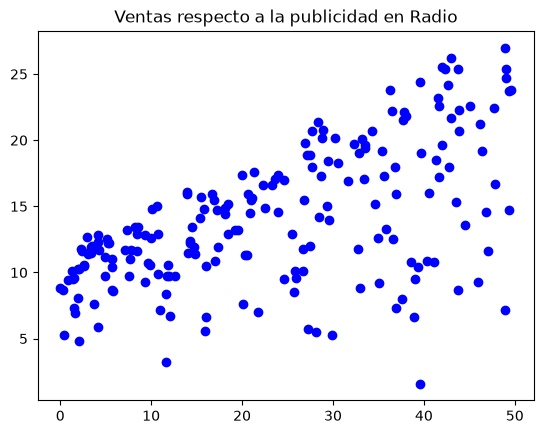

In [25]:
plt.plot(data['Radio'], data['Sales'], 'bo')
plt.title('Ventas respecto a la publicidad en %s' % 'Radio')
plt.show()

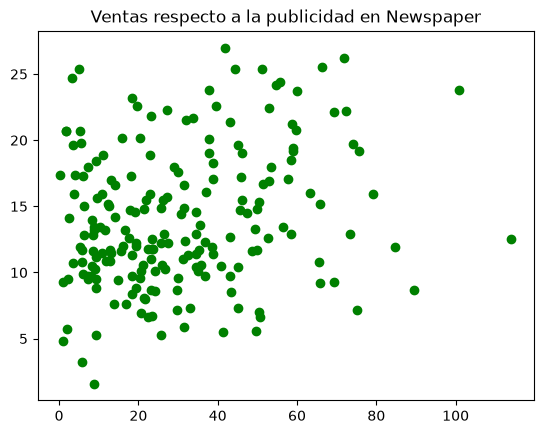

In [26]:
plt.plot(data['Newspaper'], data['Sales'], 'go')
plt.title('Ventas respecto a la publicidad en %s' % 'Newspaper')
plt.show()

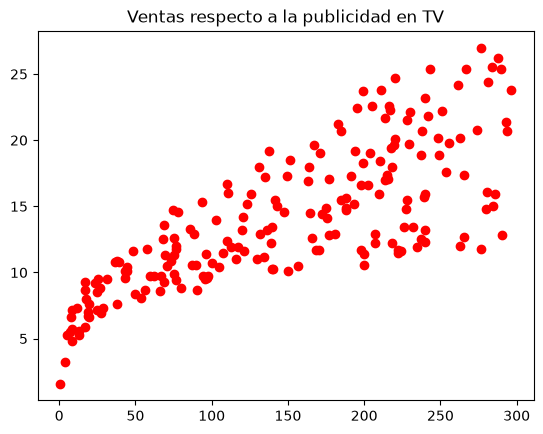

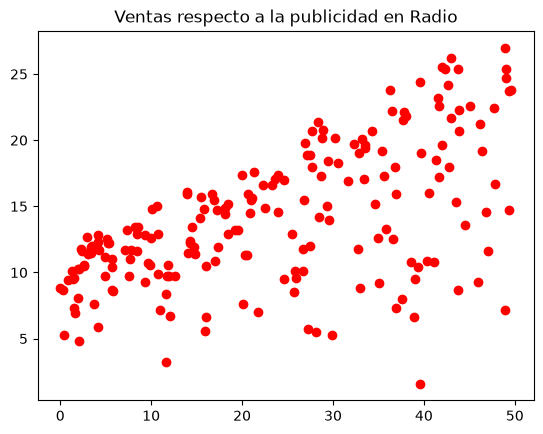

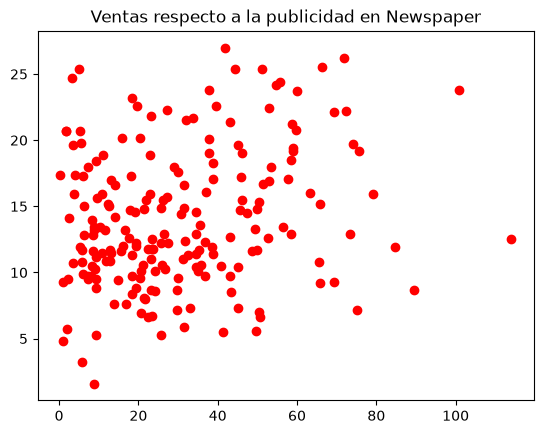

In [27]:
cols = ['TV','Radio', 'Newspaper']
for col in cols:
    plt.plot(data[col], data['Sales'], 'ro')
    plt.title('Ventas respecto a la publicidad en %s' % col)
    plt.show()
    

### **Creación de los modelos de regresión lineal simple**
### Primero crearemos los modelos de regresión lineal simple utilizando 
### cada una de las variables independientes de nuestros conjuntos de datos

### **TV**


In [26]:
# Creacion de los modelos de regresion lineal simple
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [27]:
X = data['TV'].values
X

array([230.1,  44.5,  17.2, 151.5, 180.8,   8.7,  57.5, 120.2,   8.6,
       199.8,  66.1, 214.7,  23.8,  97.5, 204.1, 195.4,  67.8, 281.4,
        69.2, 147.3, 218.4, 237.4,  13.2, 228.3,  62.3, 262.9, 142.9,
       240.1, 248.8,  70.6, 292.9, 112.9,  97.2, 265.6,  95.7, 290.7,
       266.9,  74.7,  43.1, 228. , 202.5, 177. , 293.6, 206.9,  25.1,
       175.1,  89.7, 239.9, 227.2,  66.9, 199.8, 100.4, 216.4, 182.6,
       262.7, 198.9,   7.3, 136.2, 210.8, 210.7,  53.5, 261.3, 239.3,
       102.7, 131.1,  69. ,  31.5, 139.3, 237.4, 216.8, 199.1, 109.8,
        26.8, 129.4, 213.4,  16.9,  27.5, 120.5,   5.4, 116. ,  76.4,
       239.8,  75.3,  68.4, 213.5, 193.2,  76.3, 110.7,  88.3, 109.8,
       134.3,  28.6, 217.7, 250.9, 107.4, 163.3, 197.6, 184.9, 289.7,
       135.2, 222.4, 296.4, 280.2, 187.9, 238.2, 137.9,  25. ,  90.4,
        13.1, 255.4, 225.8, 241.7, 175.7, 209.6,  78.2,  75.1, 139.2,
        76.4, 125.7,  19.4, 141.3,  18.8, 224. , 123.1, 229.5,  87.2,
         7.8,  80.2,

In [28]:
X =  data['TV'].values.reshape(-1,1)
X

array([[230.1],
       [ 44.5],
       [ 17.2],
       [151.5],
       [180.8],
       [  8.7],
       [ 57.5],
       [120.2],
       [  8.6],
       [199.8],
       [ 66.1],
       [214.7],
       [ 23.8],
       [ 97.5],
       [204.1],
       [195.4],
       [ 67.8],
       [281.4],
       [ 69.2],
       [147.3],
       [218.4],
       [237.4],
       [ 13.2],
       [228.3],
       [ 62.3],
       [262.9],
       [142.9],
       [240.1],
       [248.8],
       [ 70.6],
       [292.9],
       [112.9],
       [ 97.2],
       [265.6],
       [ 95.7],
       [290.7],
       [266.9],
       [ 74.7],
       [ 43.1],
       [228. ],
       [202.5],
       [177. ],
       [293.6],
       [206.9],
       [ 25.1],
       [175.1],
       [ 89.7],
       [239.9],
       [227.2],
       [ 66.9],
       [199.8],
       [100.4],
       [216.4],
       [182.6],
       [262.7],
       [198.9],
       [  7.3],
       [136.2],
       [210.8],
       [210.7],
       [ 53.5],
       [261.3],
       [

In [29]:
X =  data['TV'].values.reshape(-1,1)
y = data['Sales'].values

In [49]:
# Dividimos el conjunto entre el conjunto de entrenamiento y testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [50]:
print(X_train.shape)  ##Entrenar
print(X_test.shape)   ##Test

(160, 1)
(40, 1)


In [51]:
# Entrenamineto del modelo lineal con  los datos
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.05]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,7.12
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[1064.48]


In [52]:
predict = lin_reg.predict(X_test)
predict ## Valores de publicidad gastada

array([14.71794394, 16.2115484 , 20.74819743,  7.66403631, 17.37013877,
       10.61402143, 17.2072847 ,  9.44612512, 17.46785121, 15.2669948 ,
        8.58532504,  9.73460946, 18.03086098,  7.37089899, 13.61053628,
       15.03899911,  7.45930549, 16.31391381, 10.62332738, 18.16579721,
       17.79821232, 10.27435438,  8.88776831, 18.79394862, 10.33019006,
        9.60897918, 17.05373658, 13.60123034, 11.17703121,  7.51048819,
       16.41627922, 10.339496  , 16.37440246,  7.90599093, 20.18053468,
       18.203021  ,  9.36702457, 19.85482655, 12.57292322,  8.39920611])

In [53]:
# Predicciones de los valores utilizando el modelo
y_pred = lin_reg.predict(X_test)
print('Predicciones: {}, valores reales: {}' .format(y_pred[:4], y_test[:4]))
                          

Predicciones: [14.71794394 16.2115484  20.74819743  7.66403631], valores reales: [16.9 22.4 21.4  7.3]


In [ ]:
"""RMSE nos indica cuanto varian en promedio las predicciones del modelo con respecto a los valores reales
un valor mas bajo indica una mejor precision del modelo""" 
# LOs datos de pruebas no se mezclan con los de entrenamiento

In [54]:
# RMSE
from sklearn.metrics import mean_squared_error
import numpy as np

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print("RMSE: " , rmse)

RMSE:  3.194472431998898


In [55]:
r2c = r2_score(y_test, y_pred)
print('R2: ', r2c)

R2:  0.6766954295627077


In [57]:
from sklearn.metrics import root_mean_squared_error

# R2
r_squared = lin_reg.score(X_test, y_test)

# RMSE (nuevo metodo)
rmse = root_mean_squared_error(y_test, y_pred)

print(r_squared, rmse)

0.6766954295627077 3.194472431998898


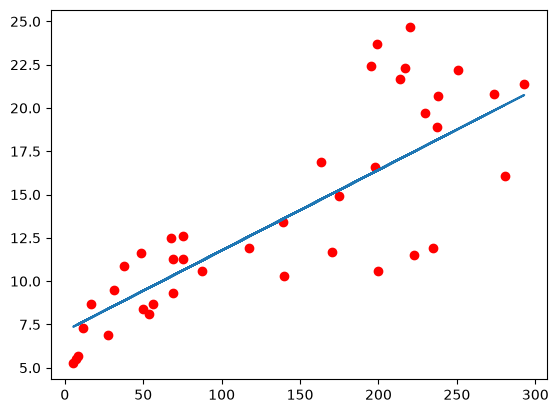

In [58]:
# Grafico de los datos de test contar el modelo
plt.plot(X_test, y_test, 'ro')
plt.plot(X_test, y_pred.reshape(-1,1))
plt.show()

In [ ]:
# Presicion: A mayor despersion menos presicion
# Exactitud: A mayor exactitud menor presicion

(160, 1)
(40, 1)
Predicciones: [15.47167765 15.47167765 14.89203768 15.01155108], valores reales: [16.9 22.4 21.4  7.3]
RMSE: 5.533600454969853
R2: 0.029871749149522397
0.029871749149522397 5.533600454969853


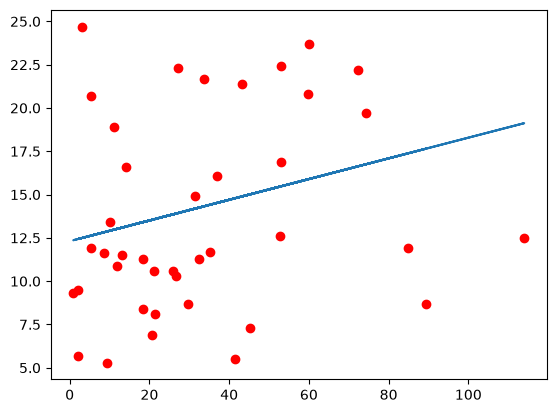

In [64]:
X = data['Newspaper'].values.reshape(-1,1)
y = data['Sales'].values
# Dividimos el conjunto entre el conjunto de entrenamiento y testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape) ## Entrenar
print(X_test.shape) ## Test
# Entrenamiento del modelo Lineal con los datos
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
predict = lin_reg.predict(X_test)
predict.reshape ## Valores de Publicidad Gastada
# Prediccion de los valores utilizando el modelo
y_pred = lin_reg.predict(X_test)
print('Predicciones: {}, valores reales: {}'.format(y_pred[:4], y_test[:4]))
# Los datos de prueba no se mezclan con los de entrenamiento - NO SE TOCAN
# RMSE
from sklearn.metrics import mean_squared_error
import numpy as np

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print("RMSE:", rmse)
##R2
r2C = r2_score(y_test, y_pred)
print('R2:', r2C)

from sklearn.metrics import root_mean_squared_error

# R2
r_squared = lin_reg.score(X_test, y_test)

# RMSE (nuevo metodo)
rmse = root_mean_squared_error(y_test, y_pred)

print(r_squared, rmse)

r2_score(y_test, y_pred) # R¨2
# Grafico de los datos de test contra el modelo
plt.plot(X_test, y_test, 'ro')
plt.plot(X_test, y_pred.reshape(-1,1))
plt.show()

(160, 1)
(40, 1)
Predicciones: [15.88332197 19.17427219 15.20877938 16.96667826], valores reales: [16.9 22.4 21.4  7.3]
RMSE: 4.8216974799471926
R2: 0.2634309396999791
0.2634309396999791 4.8216974799471926


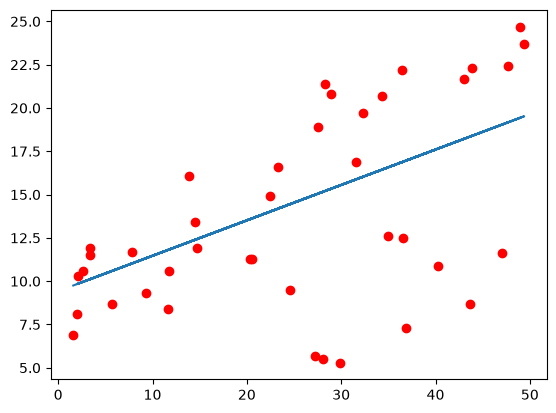

In [65]:
X = data['Radio'].values.reshape(-1,1)
y = data['Sales'].values
# Dividimos el conjunto entre el conjunto de entrenamiento y testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape) ## Entrenar
print(X_test.shape) ## Test
# Entrenamiento del modelo Lineal con los datos
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
predict = lin_reg.predict(X_test)
predict.reshape ## Valores de Publicidad Gastada
# Prediccion de los valores utilizando el modelo
y_pred = lin_reg.predict(X_test)
print('Predicciones: {}, valores reales: {}'.format(y_pred[:4], y_test[:4]))
# Los datos de prueba no se mezclan con los de entrenamiento - NO SE TOCAN
# RMSE
from sklearn.metrics import mean_squared_error
import numpy as np

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print("RMSE:", rmse)
##R2
r2C = r2_score(y_test, y_pred)
print('R2:', r2C)

from sklearn.metrics import root_mean_squared_error

# R2
r_squared = lin_reg.score(X_test, y_test)

# RMSE (nuevo metodo)
rmse = root_mean_squared_error(y_test, y_pred)

print(r_squared, rmse)

r2_score(y_test, y_pred) # R¨2
# Grafico de los datos de test contra el modelo
plt.plot(X_test, y_test, 'ro')
plt.plot(X_test, y_pred.reshape(-1,1))
plt.show()

### Conclusión
#### Dado el dataset TV resenta el margen de error más bajo RMSE de 3.19 y un R2 de 0.68, lo que indica una relación fuerte con ventas, lo que es el medio mas confiable.
#### _Radio_ es un canal de apoyo, genera un modelo débil (R2 de 0.26). Su impacto en las ventas existe, pero no es determinante.
#### _Newspaper_ es irrelevante, la inversión en este medio no se traduce de forma lineal en ventas, por lo que es el menos eficiente. tiene un error cuadratico de 0.03 
#### lo que demuestra que solo explica el 3% de la variación en las ventas dejando un 97% sin explicación y registra el margen de error más elevado RMSE = 5.53$
